In [31]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")   

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED,POINTS ,SLIPPAGE_POINTS,SPREAD_FLOOR,REPORTS
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import kurtosis


In [33]:
df = pd.read_parquet(PROCESSED)

In [34]:
#Candle info
df["r"] = np.log(df["close"] / df["close"].shift(1)) *100
df = df.dropna()
df["r"].describe().round(5)

count    479968.00000
mean          0.00021
std           0.06857
min          -2.12514
25%          -0.02655
50%           0.00050
75%           0.02751
max           2.85712
Name: r, dtype: float64

In [35]:
#Curtosis
curt=kurtosis(df["r"].dropna(),fisher=False)
#Extreme
sigma = df["r"].std()
extreme_candle = df["r"].abs() > 4 * sigma     
extreme =extreme_candle.mean() * 100  
print(f"Curtosis value: {curt.round(2)}")
print(f"The % of extreme candles is {extreme.round(2)}%")


Curtosis value: 48.39
The % of extreme candles is 0.74%


Text(0, 0.5, '€')

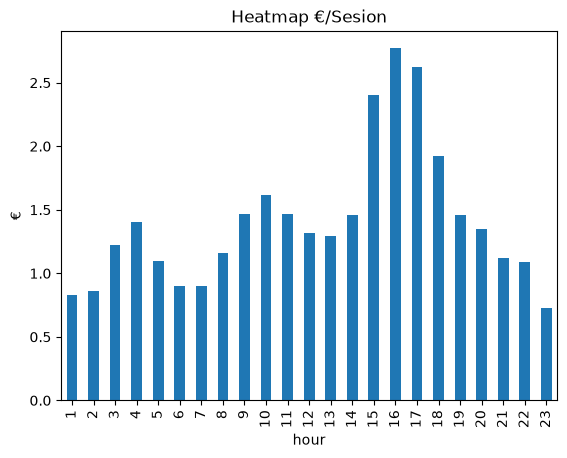

In [36]:
#Volatility per H and Y 
df["rango"]= df["high"] - df["low"]
g = df.groupby(df.index.hour)["rango"]
vol_hour = pd.DataFrame({"mediana": g.median(),
              "p95": g.quantile(0.95)})

vol_hour["mediana"].plot(kind="bar")
plt.title("Heatmap €/Sesion")           
plt.xlabel("hour")                        
plt.ylabel("€") 
              

Text(0, 0.5, '€ movements')

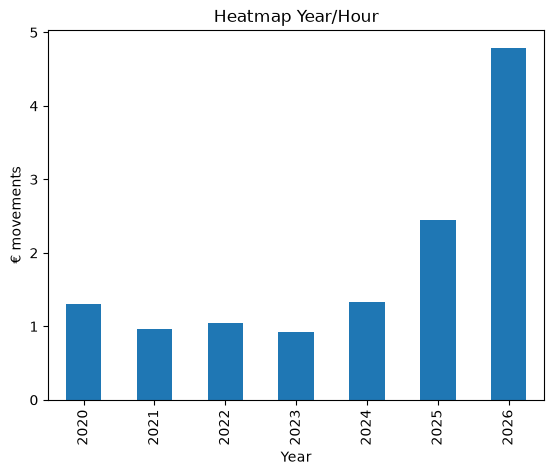

In [37]:
df["rango"]= df["high"] - df["low"]
g = df.groupby(df.index.year)["rango"]
vol_year = pd.DataFrame({"mediana": g.median(),
              "p95": g.quantile(0.95)})

vol_year["mediana"].plot(kind="bar")
plt.title("Heatmap Year/Hour")           
plt.xlabel("Year")                        
plt.ylabel("€ movements") 

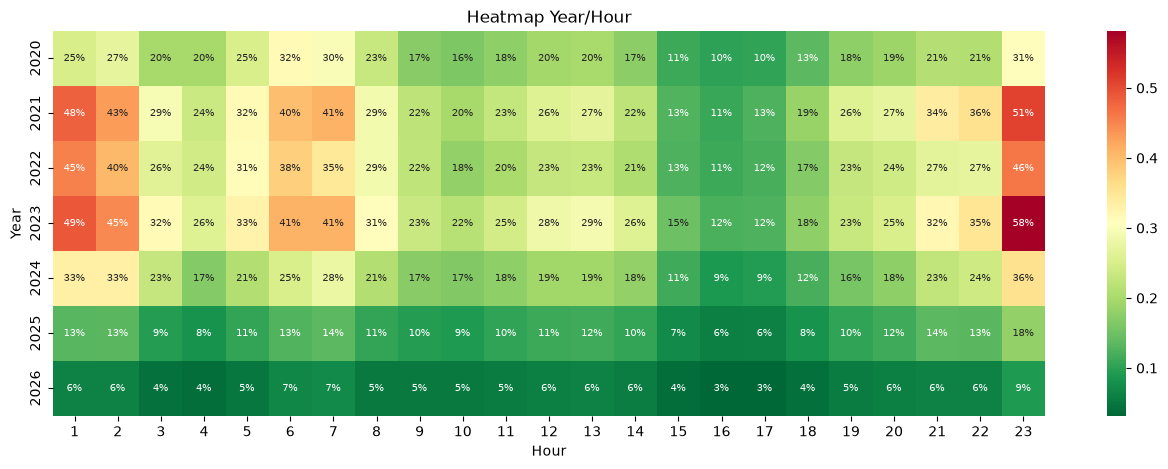

In [38]:
heatmap = df.groupby([df.index.year, df.index.hour])["rango"].median().unstack()
cost =  (((SPREAD_FLOOR + SLIPPAGE_POINTS) * POINTS) / heatmap)
plt.figure(figsize=(16, 5))  
sns.heatmap(cost,
            annot=True,
            annot_kws={"size": 7}, 
            fmt=".0%",
            cmap="RdYlGn_r")
plt.title("Heatmap Year/Hour")           
plt.xlabel("Hour")                        
plt.ylabel("Year")
plt.savefig(REPORTS / "relative_cost_hour_year.png", dpi=150, bbox_inches="tight")                        
plt.show() 

In [39]:
def acf_rapida(serie, n_lags=20, titulo=""):
    """Calcula la ACF lag a lag con pandas y la pinta con la banda de ruido al 95 %."""
    serie = serie.dropna()
    lags = range(1, n_lags + 1)
    acf = pd.Series([serie.autocorr(lag=l) for l in lags], index=lags)  # autocorrelación de cada lag
    banda = 1.96 / np.sqrt(len(serie))                                   # límite del ruido

    acf.plot(kind="bar", figsize=(10, 4))
    plt.axhline(banda, color="red", ls="--")
    plt.axhline(-banda, color="red", ls="--")
    plt.axhline(0, color="black", lw=0.8)
    plt.title(titulo)
    plt.xlabel("lag (velas)")
    plt.ylabel("autocorrelación")
    plt.show()
    return acf

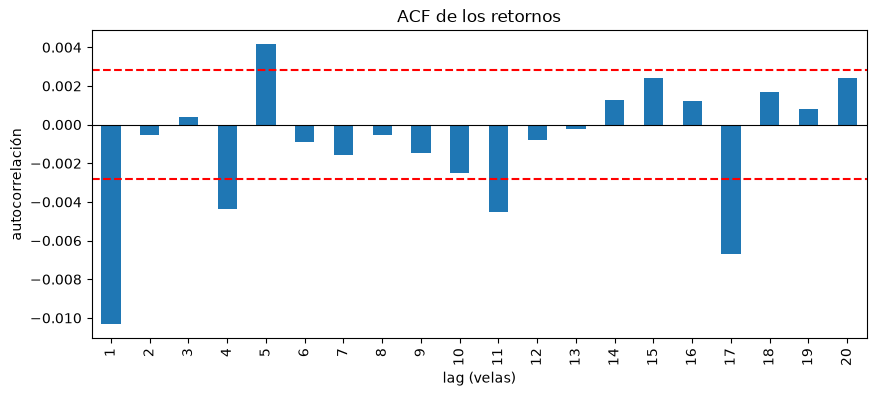

1   -0.010333
2   -0.000521
3    0.000412
4   -0.004349
5    0.004151
dtype: float64

In [40]:
acf_r = acf_rapida(df["r"], titulo="ACF de los retornos")
acf_r.head(5)

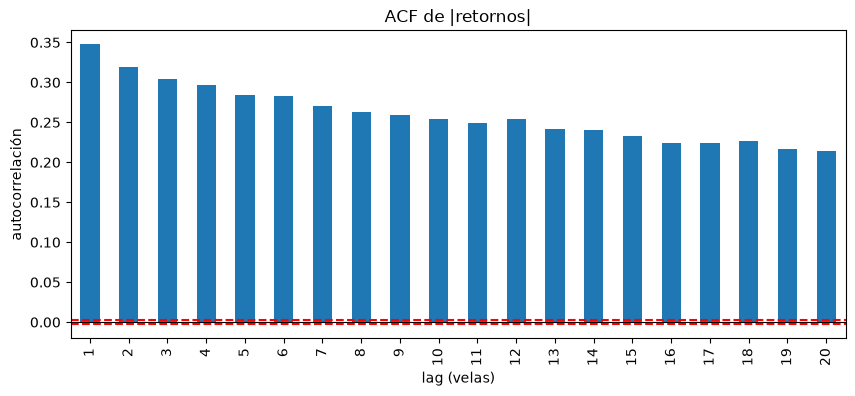

1    0.347558
2    0.319884
3    0.304382
4    0.296527
5    0.284074
dtype: float64

In [41]:
acf_abs = acf_rapida(df["r"].abs(), titulo="ACF de |retornos|")
acf_abs.head(5)

In [42]:
df.groupby(df.index.year)["r"].apply(lambda s: s.autocorr(lag=1)*100)

datetime
2020   -4.298286
2021   -2.549966
2022   -2.405475
2023    1.093349
2024   -0.287246
2025    0.540684
2026    0.405580
Name: r, dtype: float64

In [43]:
def hurst(precio_log, max_lag=100):
    """Exponente de Hurst: pendiente de log(dispersión) frente a log(lag)."""
    x = precio_log.values
    lags = np.arange(2, max_lag)
    tau = [np.std(x[lag:] - x[:-lag]) for lag in lags]    # dispersión del cambio de precio a cada lag
    return np.polyfit(np.log(lags), np.log(tau), 1)[0]    # pendiente = H

df["logp"] = np.log(df["close"])
df.groupby(df.index.year)["logp"].apply(hurst)

datetime
2020    0.493892
2021    0.482761
2022    0.495004
2023    0.507951
2024    0.500024
2025    0.497447
2026    0.491537
Name: logp, dtype: float64

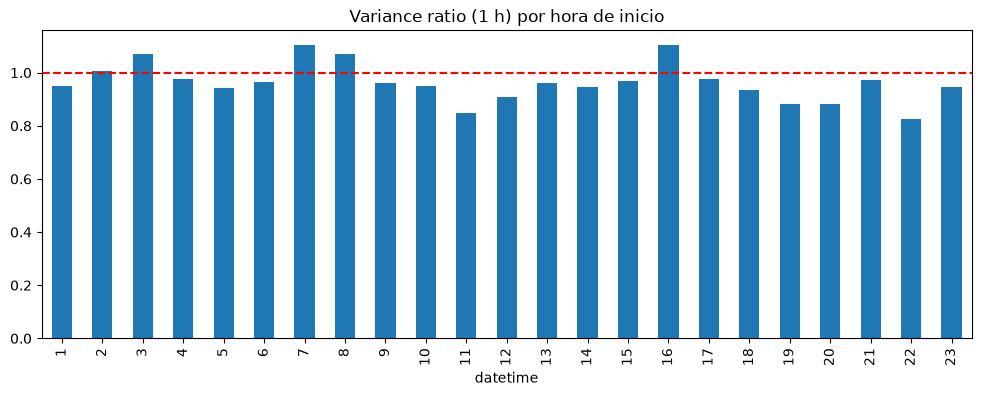

datetime
1     0.950
2     1.006
3     1.072
4     0.978
5     0.942
6     0.965
7     1.104
8     1.069
9     0.962
10    0.949
11    0.848
12    0.907
13    0.962
14    0.945
15    0.968
16    1.103
17    0.976
18    0.935
19    0.882
20    0.883
21    0.974
22    0.827
23    0.946
dtype: float64

In [44]:
q = 12
r_fut = df["r"].rolling(q).sum().shift(-(q - 1))              # retorno de las 12 velas siguientes (empezando en t)
var_real = (df["r"] ** 2).rolling(q).sum().shift(-(q - 1))    # suma de las varianzas vela a vela en esa ventana

tmp = pd.DataFrame({"r_fut2": r_fut ** 2, "var_real": var_real}).dropna()
g = tmp.groupby(tmp.index.hour)
vr_hora = g["r_fut2"].mean() / g["var_real"].mean()           # VR por hora de inicio
vr_hora.plot(kind="bar", figsize=(12, 4))
plt.axhline(1, color="red", ls="--")                          # 1 = paseo aleatorio
plt.title("Variance ratio (1 h) por hora de inicio")
plt.show()
vr_hora.round(3)

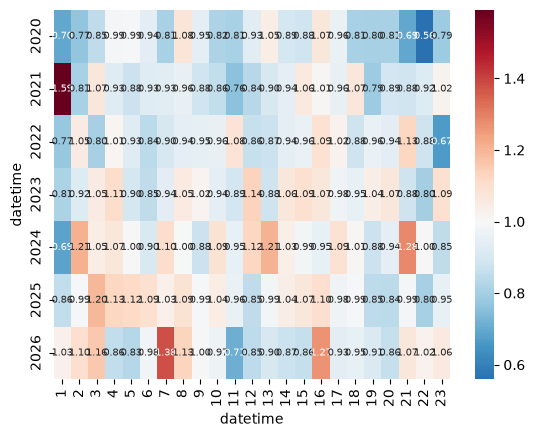

In [45]:
vr_hora_anio = (tmp.groupby([tmp.index.year, tmp.index.hour])["r_fut2"].mean()
                / tmp.groupby([tmp.index.year, tmp.index.hour])["var_real"].mean()).unstack()
sns.heatmap(vr_hora_anio, cmap="RdBu_r", center=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.show()

In [46]:
df.groupby(df.index.year)["r"].apply(lambda s: s.autocorr(lag=1)*100)

datetime
2020   -4.298286
2021   -2.549966
2022   -2.405475
2023    1.093349
2024   -0.287246
2025    0.540684
2026    0.405580
Name: r, dtype: float64

In [48]:
def half_life(x):
    """Half-life (en velas) de un proceso OU estimado con Δx_t = a + b·x_{t-1}."""
    x = x.dropna().values
    dx = np.diff(x)                         # Δx_t
    b = np.polyfit(x[:-1], dx, 1)[0]        # pendiente de la regresión
    return -np.log(2) / np.log(1 + b)       # velas hasta recorrer la mitad del camino

In [49]:
rng = np.random.default_rng(42)
r_barajado = rng.permutation(df["r"].values)                       # mismos retornos, orden aleatorio
logp_placebo = pd.Series(np.cumsum(r_barajado), index=df.index)    # precio "sin memoria"

filas = []
for n in [12, 24, 48, 96]:                                         # EMA de 1 h, 2 h, 4 h y 8 h
    x_real = df["logp"] - df["logp"].ewm(span=n, adjust=False).mean()
    x_plac = logp_placebo - logp_placebo.ewm(span=n, adjust=False).mean()
    filas.append({"ema": n,
                  "hl_real": half_life(x_real),
                  "hl_placebo": half_life(x_plac)})

hl = pd.DataFrame(filas).set_index("ema")
hl["ratio"] = hl["hl_real"] / hl["hl_placebo"]    # < 1 → revierte más rápido que el azar
hl.round(2)

,hl_real,hl_placebo,ratio
ema,,,
12,4.03,4.13,0.98
24,8.03,8.25,0.97
48,15.98,16.45,0.97
96,31.96,32.92,0.97


In [50]:
x_real = df["logp"] - df["logp"].ewm(span=48, adjust=False).mean()
x_plac = logp_placebo - logp_placebo.ewm(span=48, adjust=False).mean()

res = {}
for h in [11, 16, 22]:
    mask = df.index.hour == h                       # solo las velas de esa hora
    res[h] = {"hl_real": half_life(x_real[mask]),
              "hl_placebo": half_life(x_plac[mask])}
pd.DataFrame(res).T.round(2)

,hl_real,hl_placebo
11,5.39,5.65
16,4.91,5.45
22,5.37,5.38
